# 02 — Raw race data EDA

**Goal:** understand the raw race laps well enough to write the spec for the processed layer, for Stage 1 (lap-time / degradation model; see `docs/ROADMAP.md`).
Data: **92 races (2022–2025), ~101k race laps.**

## Findings so far (Q1–Q7)

**Identity**
- One row = one lap of one driver in one race. Key candidate: `(Season, Round, Driver, LapNumber)`.
- `Round` is only unique **within a season** → always group by `Season` + `Round`.
- Max `LapNumber` per driver shows retirements (e.g. Bahrain 2022: GAS 45, VER 54 of 57).

**Time columns** (raw = integer nanoseconds → converted to `*_sec` below)
- Durations: `LapTime`, `Sector1/2/3Time`: how long something took.
- Session clock: `Time` (lap end), `LapStartTime`, `PitInTime`, `PitOutTime`: *when* it happened, on a stopwatch that starts ~1 h before the race. Its mean/std mean nothing; use differences.
- `LapStartDate` is empty for every row (needs telemetry, not loaded) → drop.
- Sector times and speed traps are measured *during* the lap → leakage if used to predict that lap.

**Lap quality**
- `LapTime` missing on ~1.5% of laps, concentrated in a few races (top: 2022 R17, 108 laps), mostly **safety-car** laps, the rest mostly red flags.
- `TrackStatus` is a string of every status during the lap, in order. Code book: 1 all clear, 2 yellow, 4 SC, 5 red, 6 VSC, 7 VSC ending. ~40 combinations → become yes/no flags (yellow / SC / VSC / red in lap), not 40 categories.
- Mean lap: green ≈ 89.7 s, SC ≈ 122.8 s, VSC ≈ 119.7 s; red-flag laps up to 41 min or missing.
- `IsAccurate` false on 13.6% of laps; `Deleted` on 1.3% (almost all track limits).

**Pit stops**
- In-lap ≈ +2.5 s, out-lap ≈ +18 s (VER, Bahrain 2022) → **pit loss, not degradation**; exclude from degradation, reuse for the simulator.
- The laps **around** a stop show degradation: last lap on old tyres 99.5 s → first lap on new tyres 96.9 s (2.6 s).

**Tyres**
- Compounds: HARD, MEDIUM, SOFT, plus INTERMEDIATE (~5.9k laps) and WET (~0.5k) → wet flag.
- `"None"` and `"nan"` in `Compound` are **text strings, not missing values** → clean in processed layer.
- `Stint` = tyre-set counter (steps up at each stop), not degradation.
- `TyreLife` = age of the current set, resets at each stop; used sets (`FreshTyre = False`) start older.

**Weather**
- One reading every ~60 s on the session clock → attach the latest reading before each lap's start.
- Track temp varies a little within a race (Bahrain 2022: 26–32 °C) and a lot **between** races (17–54 °C) → feature.
- `Rainfall` appears in some races; track is cooler when it rains.

**Open threads** (for later)
1. Confirm `(Season, Round, Driver, LapNumber)` is unique.
2. Why some green-flag laps miss a lap time (2022 R18, 2023 R3).
3. Degradation gap across every pit stop (`groupby().shift()`).
4. Deleted laps: keep or exclude for degradation?
5. Stint-length distribution: are very short stints useful?
6. Rain sensor vs wet tyres: which marks a wet lap better?
7. `IsAccurate`: does it add anything beyond pit / lap-1 / track-status flags?


In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from f1_intelligence.config import load_ingestion_config

RAW = load_ingestion_config("../configs/ingestion.yaml").storage.raw_uri


def raw_table(table: str, session: str = "R") -> pd.DataFrame:
    """All ingested sessions of one raw table, as a single DataFrame."""
    return duckdb.sql(f"""
        SELECT *
        FROM read_parquet('{RAW}/{table}/**/*.parquet', hive_partitioning = true, union_by_name = true)
        WHERE Session = '{session}'
    """).df()


meta = duckdb.sql(f"""
    SELECT season AS Season, round AS Round, event_name, location, event_format, session_start_utc
    FROM read_json('{RAW}/metadata/**/*.json', hive_partitioning = false)
    WHERE session = 'R'
""").df()

laps = raw_table("laps").merge(meta, on=["Season", "Round"], how="left")
weather = raw_table("weather")
results = raw_table("results")
track_status = raw_table("track_status")
race_control = raw_table("race_control")

print(f"{meta.shape[0]} races | {len(laps):,} laps | seasons {sorted(meta.Season.unique())}")
{name: df.shape for name, df in dict(laps=laps, weather=weather, results=results,
                                      track_status=track_status, race_control=race_control).items()}

92 races | 101,290 laps | seasons [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


{'laps': (101290, 38),
 'weather': (14896, 11),
 'results': (1838, 25),
 'track_status': (1092, 6),
 'race_control': (8156, 12)}

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 60)

# Raw time columns are integer nanoseconds; add a seconds version of each.
for col in ["Time", "LapTime", "LapStartTime", "PitInTime", "PitOutTime",
            "Sector1Time", "Sector2Time", "Sector3Time"]:
    laps[f"{col}_sec"] = laps[col] / 1e9
weather["Time_sec"] = weather["Time"] / 1e9
track_status["Time_sec"] = track_status["Time"] / 1e9

# Example race used throughout: Bahrain 2022 (season opener)
bahrain_22 = laps[(laps["Season"] == 2022) & (laps["Round"] == 1)].copy()
three_drivers = bahrain_22[bahrain_22["Driver"].isin(["VER", "LEC", "HAM"])]

## Q1 — What is one row?
Columns, dtypes, laps per race, key uniqueness.

In [ ]:
laps.head()

In [ ]:
laps.info()

In [ ]:
# Race length per race (Round alone is ambiguous across seasons)
laps.groupby(["Season", "Round", "event_name"])["LapNumber"].max()

In [ ]:
# Laps completed per driver in one race: shows retirements
bahrain_22.groupby("Driver")["LapNumber"].max().sort_values()

## Q2 — Missing values
Which columns, and in which kind of laps?

In [ ]:
laps.isna().sum()[lambda s: s > 0].sort_values(ascending=False)

In [ ]:
# Missing lap times by lap number (all races together)
laps.loc[laps["LapTime"].isna(), "LapNumber"].value_counts().head(15)

In [ ]:
# Missing lap times per race
laps[laps["LapTime"].isna()].groupby(["Season", "Round", "event_name"]).size().sort_values(ascending=False).head(10)

In [ ]:
# Missing lap times per race and track status
laps[laps["LapTime"].isna()].groupby(["Season", "Round", "TrackStatus"]).size().sort_values(ascending=False).head(20)

## Q3 — Track status
What the digits mean, and how lap times differ by status.

In [ ]:
# Code book: one digit per status
track_status[["Status", "Message"]].drop_duplicates().sort_values("Status")

In [ ]:
# Lap time per TrackStatus combination
laps.groupby("TrackStatus")["LapTime_sec"].agg(["count", "mean"]).sort_values("mean", ascending=False)

## Q4 — Pit laps and lap 1
In-lap, out-lap, and the laps either side of each stop (VER, Bahrain 2022).

In [ ]:
ver = bahrain_22[bahrain_22["Driver"] == "VER"]
is_pit_lap = ver["PitInTime"].notna() | ver["PitOutTime"].notna()
around_stop = is_pit_lap | is_pit_lap.shift(1, fill_value=False) | is_pit_lap.shift(-1, fill_value=False)

ver.loc[around_stop, ["LapNumber", "Stint", "Compound", "TyreLife", "LapTime_sec",
                      "PitInTime_sec", "PitOutTime_sec", "TrackStatus"]]

## Q5 — Outliers and what is "normal"

In [ ]:
print(laps["IsAccurate"].value_counts(), "\n")
print(laps["Deleted"].value_counts(), "\n")
laps["DeletedReason"].value_counts().head(10)

In [ ]:
sns.lineplot(data=three_drivers, x="LapNumber", y="LapTime_sec", hue="Driver")
plt.title("Lap time across the race, Bahrain 2022")
plt.ylabel("Lap time (s)")
plt.show()

In [ ]:
sns.histplot(data=three_drivers, x="LapTime_sec", hue="Driver", bins=60)
plt.title("Lap time distribution, Bahrain 2022")
plt.show()

## Q6 — Tyres and stints

In [ ]:
laps["Compound"].value_counts(dropna=False)

In [ ]:
sns.lineplot(data=three_drivers, x="LapNumber", y="Stint", hue="Driver")
plt.title("Stint counter steps up at each pit stop")
plt.show()

In [ ]:
sns.lineplot(data=three_drivers, x="LapNumber", y="TyreLife", hue="Driver")
plt.title("TyreLife resets at each pit stop")
plt.show()

In [ ]:
# Share of laps run on a fresh (new) set, by lap number
laps.groupby("LapNumber")["FreshTyre"].mean().plot(title="Share of laps on fresh tyres")
plt.show()

## Q7 — Weather

In [ ]:
weather.head(10)  # readings ~60 s apart on the session clock

In [ ]:
bahrain_22_weather = weather[(weather["Season"] == 2022) & (weather["Round"] == 1)]
print(bahrain_22_weather["TrackTemp"].describe())
bahrain_22_weather.plot(x="Time_sec", y="TrackTemp", title="Track temperature during Bahrain 2022")
plt.show()

In [ ]:
# Mean track temperature per race, summarised across races
weather.groupby(["Season", "Round"])["TrackTemp"].mean().describe()

In [ ]:
# Races with any rain reading, and track temperature with vs without rain
rain_races = weather.groupby(["Season", "Round"])["Rainfall"].any()
rain_races = rain_races[rain_races].index
(weather.set_index(["Season", "Round"]).loc[rain_races]
        .groupby(["Season", "Round", "Rainfall"])["TrackTemp"].agg(["count", "mean"]))

## Q8 — Fuel effect
- Using only clean laps (no pit laps, lap 1, or non-green laps), plot lap time vs `LapNumber` for one race.
- Does the car get faster as fuel burns, even while tyres age? Roughly how much per lap?
- Why does this matter for estimating degradation? (Your first notebook found a correlation of only −0.04 between `TyreLife` and lap time.)

In [5]:
laps.columns

Index(['Season', 'Round', 'Session', 'Time', 'Driver', 'DriverNumber',
       'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime',
       'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime',
       'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2',
       'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife',
       'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus',
       'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate',
       'event_name', 'location', 'event_format', 'session_start_utc'],
      dtype='object')

In [9]:
laps['Driver'] == 'VER'

0          True
1          True
2          True
3          True
4          True
          ...  
101285    False
101286    False
101287    False
101288    False
101289    False
Name: Driver, Length: 101290, dtype: bool

In [23]:
laps["LapTime_sec"] = laps["LapTime"] / 1e9

In [37]:
ver1_df = laps.query("Season == 2022 & (Round == 1) & (Driver == 'VER')")


In [38]:
ver1_df = ver1_df.query("(LapNumber > 1) & (LapTime_sec.notna()) & (PitInTime.isna()) & (PitOutTime.isna()) & (TrackStatus == '1') & (Compound.isin(['SOFT', 'MEDIUM', 'HARD']))")

<Axes: xlabel='LapNumber', ylabel='LapTime_sec'>

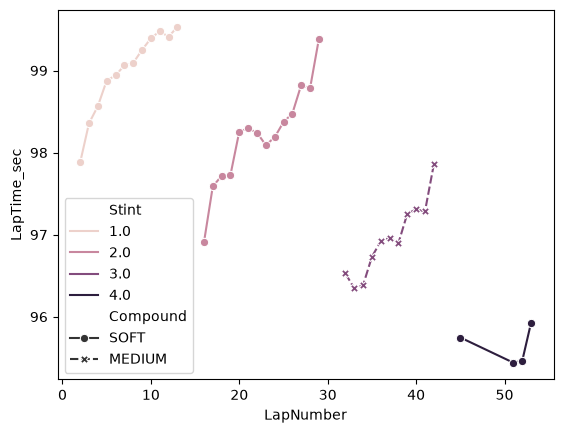

In [48]:
sns.lineplot(data=ver1_df, x="LapNumber", y="LapTime_sec", hue="Stint"
             ,style="Compound", markers=True)


In [ ]:
ver1_df.sort_values("LapNumber").groupby(["Stint", "Compound"])['LapTime_sec'].first()

Stint  Compound
1.0    SOFT         97.88
2.0    SOFT        96.905
3.0    MEDIUM      96.527
4.0    SOFT        95.747
Name: LapTime_sec, dtype: Float64

In [ ]:
ver1_df.sort_values("LapNumber").groupby(["Stint", "Compound"]).head(3).groupby(["Stint", "Compound"])['LapTime_sec'].mean()

## Q9 — Traffic
- For one race, compute each driver's gap to the car ahead on every lap. (`Time` is when the driver crossed the line; `Position` tells you who is ahead.)
- Plot gap vs lap time. Is there a gap below which drivers are visibly slower?

In [77]:
laps.columns

Index(['Season', 'Round', 'Session', 'Time', 'Driver', 'DriverNumber',
       'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime',
       'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime',
       'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2',
       'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife',
       'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus',
       'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate',
       'event_name', 'location', 'event_format', 'session_start_utc',
       'LapTime_sec'],
      dtype='object')

In [4]:
laps['Time_sec'] = laps['Time'] / 1e9

In [78]:
s22r1_df = laps.query("(Season == 2022) & (Round == 1)")

In [79]:
pd.options.display.max_rows = 100

In [80]:
s22r1_df.sort_values(["LapNumber", "Position"]).groupby(['LapNumber', 'Position']).head(50)[["LapNumber", "Position", "Driver", "Time_sec"]]

,LapNumber,Position,Driver,Time_sec
213,1.0,1.0,LEC,3854.174
0,1.0,2.0,VER,3855.340
897,1.0,3.0,SAI,3856.110
783,1.0,4.0,HAM,3856.659
327,1.0,5.0,MAG,3857.437
...,...,...,...,...
497,57.0,13.0,ALB,9662.620
668,57.0,14.0,RIC,9663.663
782,57.0,15.0,NOR,9665.023
1010,57.0,16.0,LAT,9670.483


In [81]:
s22r1_df['gap_ahead_sec'] = s22r1_df.sort_values(["LapNumber", "Position"]).groupby(['LapNumber'])['Time_sec'].diff()

In [27]:
s22r1_df.sort_values(["LapNumber", "Position"])[["LapNumber", "Driver", "gap_ahead_sec"]]

,LapNumber,Driver,gap_ahead_sec
213,1.0,LEC,NaN
0,1.0,VER,1.166
897,1.0,SAI,0.770
783,1.0,HAM,0.549
327,1.0,MAG,0.778
...,...,...,...
668,57.0,RIC,1.043
782,57.0,NOR,1.360
1010,57.0,LAT,5.460
611,57.0,HUL,2.034


In [30]:
s22r1_df.query("(LapNumber == 5) ")[["Position", "Driver", "Time_sec", "gap_ahead_sec"]].sort_values(by=["Position"])

,Position,Driver,Time_sec,gap_ahead_sec
217,1.0,LEC,4247.184,NaN
4,2.0,VER,4249.020,1.836
901,3.0,SAI,4251.832,2.812
787,4.0,HAM,4252.551,0.719
103,5.0,PER,4254.264,1.713
1015,6.0,RUS,4256.781,2.517
331,7.0,MAG,4258.465,1.684
58,8.0,GAS,4259.918,1.453
160,9.0,ALO,4261.478,1.560
673,10.0,OCO,4262.325,0.847


In [35]:
s22r1_df = s22r1_df.query("(LapNumber > 1) & (LapTime_sec.notna()) & (PitInTime.isna()) & (PitOutTime.isna()) & (TrackStatus == '1') & (Compound.isin(['SOFT', 'MEDIUM', 'HARD']))")

<Axes: xlabel='gap_ahead_sec', ylabel='LapTime_sec'>

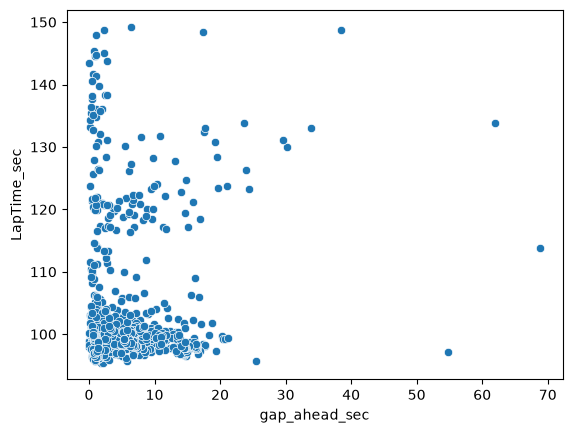

In [82]:
sns.scatterplot(data=s22r1_df, x="gap_ahead_sec", y="LapTime_sec")

## Q10 — The target: lap time vs tyre age
- For clean laps (Q8 filter) that are not in traffic (Q9), plot lap time vs `TyreLife` per compound, for a few races.
- Fit a simple slope per stint (seconds per lap of tyre age). How do slopes differ by compound and track?
- What would you need to correct for (fuel from Q8, traffic from Q9, track) before a slope means "degradation"?

In [83]:
s22r1_df = s22r1_df.query("(LapNumber > 1) & (gap_ahead_sec > 1) & (LapTime_sec.notna()) & (PitInTime.isna()) & (PitOutTime.isna()) & (TrackStatus == '1') & (Compound.isin(['SOFT', 'MEDIUM', 'HARD']))")

In [84]:
s22r1_df["TyreLife"].describe()

count    662.000000
mean       9.669184
std        4.584812
min        2.000000
25%        6.000000
50%        9.500000
75%       13.000000
max       23.000000
Name: TyreLife, dtype: float64

<Axes: xlabel='TyreLife', ylabel='fuel_corrected_lap_time'>

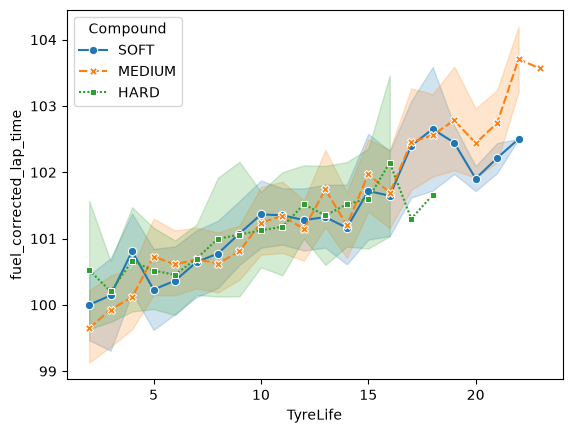

In [87]:
sns.lineplot(data=s22r1_df, y="fuel_corrected_lap_time", x="TyreLife", style="Compound", hue="Compound", markers=True)

In [86]:
s22r1_df['fuel_corrected_lap_time'] = s22r1_df['LapTime_sec'] + 0.06 * s22r1_df['LapNumber']

In [73]:
s22r1_df = s22r1_df.sort_values(["Driver", "Stint", "LapNumber"])


In [104]:
s22r1_df["stint_start"] = s22r1_df.groupby(["Driver", "Stint"])[["fuel_corrected_lap_time"]].transform(lambda x: x.head(3).mean())

In [105]:
s22r1_df['delta'] = s22r1_df['fuel_corrected_lap_time'] - s22r1_df['stint_start']

<Axes: xlabel='TyreLife', ylabel='delta'>

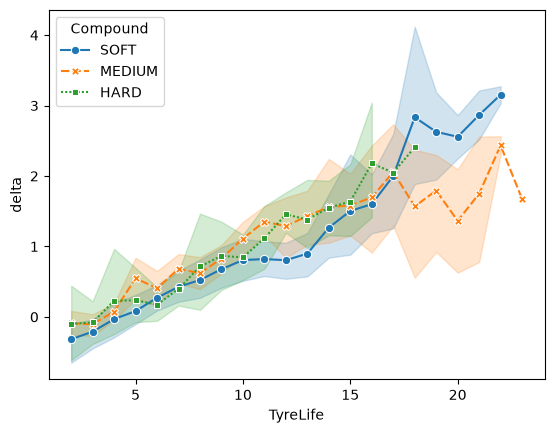

In [106]:
sns.lineplot(data=s22r1_df, y="delta", x="TyreLife", style="Compound", hue="Compound", markers=True)

In [ ]:
s22r1_df.groupby(["Driver", "Stint"])

In [108]:
import numpy as np

def stint_slope(stint):
    """Degradation rate of one stint: seconds lost per lap of tyre age."""
    if len(stint) < 5:          # too few laps to trust a line
        return np.nan
    slope, intercept = np.polyfit(stint["TyreLife"], stint["delta"], 1)
    return slope


In [110]:
slopes = (
    s22r1_df.groupby(["Driver", "Stint", "Compound"])
            .apply(stint_slope, include_groups=False)
            .rename("slope")
            .reset_index()
)
slopes.sort_values("slope", ascending=False).head(10)


,Driver,Stint,Compound,slope
20,HUL,3.0,MEDIUM,0.432600
10,BOT,3.0,MEDIUM,0.362286
3,ALB,4.0,SOFT,0.348700
70,ZHO,3.0,MEDIUM,0.318629
48,RIC,4.0,SOFT,0.318400
4,ALO,1.0,SOFT,0.300267
30,MSC,1.0,SOFT,0.298655
60,STR,4.0,SOFT,0.296300
0,ALB,1.0,SOFT,0.293491
24,LAT,4.0,SOFT,0.257700


In [111]:
slopes.groupby("Compound")["slope"].agg(["count", "median", "mean"])


,count,median,mean
Compound,,,
HARD,7,0.128082,0.137948
MEDIUM,20,0.150973,0.176476
SOFT,35,0.183507,0.177045


## Notes / open questions
